# Elastic net regression: TMDB viewer ratings
Predict `vote_average` with combined L1/L2 shrinkage to balance sparsity and correlated predictors.

Read the same feature-engineering CSV and use the same 2017-11-18 cutoff, chronological folds, numeric scaling, categorical encoding, and optional degree-2 numeric features as ridge. Coefficients are learned from training rows only. Jointly select settings and feature groups by mean validation MAE; later-test scores do not select candidates. No improvement over ridge is guaranteed.

The source data and existing deployed ridge/logistic pipelines remain unchanged. These are exploratory experiments on an already-inspected test period. [Estimator documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html).

## Tuning controls — edit here first
Save and **Run All** after changing the next cell.

- `regression__alpha`: shrinkage strength. Alpha scales differently from ridge; its numeric value is not directly comparable.
- `regression__l1_ratio` (elastic net only): mixing weight; closer to 1 adds more L1 sparsity, closer to 0 more L2 shrinkage.
- `preprocessor__numeric__polynomial__degree`: 1 for the original representation or 2 for squared terms and numeric interactions.
- `FEATURE_GROUPS_TO_COMPARE`: compare the same movie/director/actor/company groups as ridge; keep All features.
- `MODEL_SETTINGS`: original reference settings and convergence controls; `precompute=True` accelerates repeated coordinate-descent fits.
- Keep `CUTOFF_DATE` and `N_VALIDATION_SPLITS` consistent across notebooks.

Default search uses 3 chronological validation folds. Choose by MAE; evaluate RMSE and R² as secondary measures. All fits must converge; the notebook raises on convergence warnings rather than hiding them.

In [1]:
# EDIT THIS CELL, then save and Run All. Do not change settings in later cells.
DATA_FILE = "../../data/model_data_rating.csv"
CUTOFF_DATE = "2017-11-18"  # Change consistently across models for a fair comparison.
N_VALIDATION_SPLITS = 3     # Expanding chronological folds inside training.

# Fixed original-model settings. Grid values below override these during a search.
MODEL_SETTINGS = {'alpha': 0.01, 'max_iter': 50000, 'tol': 0.0001, 'precompute': True, 'l1_ratio': 0.5}

# CHANGE THESE LISTS to try model settings. More values mean a longer run.
# Joint search over feature groups, shrinkage, and numeric polynomial degree.
PARAM_GRID = {'preprocessor__numeric__polynomial__degree': [1, 2], 'regression__alpha': [0.001, 0.003, 0.01, 0.03, 0.1], 'regression__l1_ratio': [0.05, 0.2, 0.5, 0.8]}
TUNING_METRIC = "MAE"
# MAE/RMSE: lower is better. R2: higher is better.

# Remove a group to skip it; keep All features for the reference comparison.
FEATURE_GROUPS_TO_COMPARE = [
    "Movie characteristics", "+ Director history", "+ Actor history", "All features",
]
assert "All features" in FEATURE_GROUPS_TO_COMPARE

assert isinstance(N_VALIDATION_SPLITS, int) and N_VALIDATION_SPLITS >= 2

assert set(FEATURE_GROUPS_TO_COMPARE) <= {"Movie characteristics", "+ Director history", "+ Actor history", "All features"}

# Goals describe evaluation, not a rule for repeatedly adjusting against test scores.
RATING_GOALS = {"MAE": 0.50, "RMSE": 0.65, "R2": 0.30}
STRETCH_GOALS = {"MAE": 0.45, "R2": 0.40}


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import ElasticNet
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

movies = pd.read_csv(DATA_FILE, parse_dates=["release_date"])
movies = movies.sort_values("release_date", kind="stable").reset_index(drop=True)
assert movies["tmdb_id"].is_unique
assert movies["release_date"].notna().all()
assert movies["vote_average"].notna().all() and movies["vote_average"].between(0, 10).all()
print(f"Loaded {len(movies):,} movies | Target: vote_average")
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("error", category=ConvergenceWarning)


Loaded 13,276 movies | Target: vote_average


## 1. Select predictors
Exclude the current-movie outcome (`vote_average`) and movie identifiers from the inputs. Keep release year numeric and treat release month as categorical.

In [3]:
ID_COLUMNS = ["tmdb_id", "imdb_id", "title_tmdb", "release_date"]
TARGET_COLUMNS = ["vote_average"]
NUMERIC_FEATURES = [
    "runtime", "log_budget", "release_year", "n_genres", "imdb_director_count",
    "dir_prior_success_rate_smoothed", "dir_prior_rating_smoothed",
    "dir_prior_rated_films_log1p", "dir_prior_films_log1p",
    "dir_years_active_log1p", "dir_prior_known_films_log1p",
    "lead_actor_films_5yr_backfilled_log1p", "company_films_5yr_log1p",
    "franchise_prior_films_log1p",
]
CATEGORICAL_FEATURES = ["us_certification", "release_month"]
BINARY_FEATURES = [
    "is_sequel", "is_english", "dir_first_film", "dir_no_track_record", "backfill_unavailable", "dir_no_rating_history",
] + [column for column in movies if column.startswith("genre_")]
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES
assert len(FEATURE_COLUMNS) == len(set(FEATURE_COLUMNS))
assert set(movies) == set(ID_COLUMNS + TARGET_COLUMNS + FEATURE_COLUMNS)
assert not set(ID_COLUMNS + TARGET_COLUMNS) & set(FEATURE_COLUMNS)
assert not {"budget", "revenue", "revenue_to_budget", "popularity", "vote_count"} & set(FEATURE_COLUMNS)
assert movies[BINARY_FEATURES].isin([0, 1]).all().all()

X = movies[FEATURE_COLUMNS].copy()
# String conversion is a fixed type conversion, not a learned transformation.
for column in CATEGORICAL_FEATURES:
    X[column] = X[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
y = movies["vote_average"].copy()
print(f"Predictors: {len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical, {len(BINARY_FEATURES)} binary")

Predictors: 14 numeric, 2 categorical, 24 binary


## 2. Split by release date
Read `model_data_rating.csv`, built from the broader combined data without budget/revenue filters. Retain the previous experiment's fixed date cutoff **2017-11-18**: train before it and test on or after it. All movies sharing a date stay together. The expanded cohort has 9,405 training and 3,871 test movies (about 71/29, rather than the previous 80/20).

Training-only chronological folds are rebuilt within this expanded training set. Broader test-population scores are not directly comparable with earlier scores on only financially eligible movies. These data have already been inspected, so results remain exploratory.

In [4]:
cutoff = pd.Timestamp(CUTOFF_DATE)
train_mask = movies["release_date"].lt(cutoff)
test_mask = ~train_mask
X_train, X_test = X.loc[train_mask].copy(), X.loc[test_mask].copy()
y_train, y_test = y.loc[train_mask].copy(), y.loc[test_mask].copy()
assert len(X_train) > 0 and len(X_test) > 0
assert movies.loc[train_mask, "release_date"].max() < movies.loc[test_mask, "release_date"].min()
assert set(movies.loc[train_mask, "tmdb_id"]).isdisjoint(movies.loc[test_mask, "tmdb_id"])
display(pd.DataFrame([
    ["Training", int(train_mask.sum()), movies.loc[train_mask, "release_date"].min(), movies.loc[train_mask, "release_date"].max()],
    ["Test", int(test_mask.sum()), movies.loc[test_mask, "release_date"].min(), movies.loc[test_mask, "release_date"].max()],
], columns=["Split", "Movies", "First release", "Last release"]))

,Split,Movies,First release,Last release
0,Training,9405,1990-01-12,2017-11-17
1,Test,3871,2017-11-18,2025-12-28


## 3. Fit the original elastic net regression
Use the same preprocessing structure as ridge: training-only imputation, numeric standardization, optional polynomial expansion and re-scaling, categorical encoding, and binary flags. The fixed reference uses degree 1 and alpha 0.01. This is a fitted model, not a dummy baseline. The training-mean baseline remains in the evaluation table.

In [5]:
def make_regression_model(columns):
    """Fresh preprocessing and regression for each feature set and split."""
    numeric = [column for column in NUMERIC_FEATURES if column in columns]
    categorical = [column for column in CATEGORICAL_FEATURES if column in columns]
    binary = [column for column in BINARY_FEATURES if column in columns]
    assert set(numeric + categorical + binary) == set(columns)
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("polynomial", PolynomialFeatures(degree=1, include_bias=False)),
            ("expanded_scaler", StandardScaler()),
        ]), numeric),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
        ]), categorical),
        ("binary", "passthrough", binary),
    ])
    return Pipeline([
        ("preprocessor", preprocessing),
        ("regression", ElasticNet(**MODEL_SETTINGS)),
    ])

initial_model = make_regression_model(FEATURE_COLUMNS)
initial_model.fit(X_train, y_train)
initial_train_predictions = initial_model.predict(X_train)
initial_test_predictions = initial_model.predict(X_test)

baseline = DummyRegressor(strategy="mean")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
baseline_predictions = baseline.predict(np.zeros((len(y_test), 1)))
assert np.allclose(baseline_predictions, y_train.mean())
print(f"Training mean rating (baseline): {y_train.mean():.3f}")

Training mean rating (baseline): 6.399


## 4. Tune regularization and numeric representation
Search alpha and degree on the full feature set; elastic net also searches l1_ratio. Section 4b jointly compares these settings across feature groups. Do not select settings from the later-test results. Numeric missingness handling is held at the original median-imputation definition for this bounded experiment.

In [6]:
from sklearn.model_selection import GridSearchCV

# Three expanding validation windows entirely within the outer training period.
tuning_dates = movies.loc[train_mask, "release_date"]
assert tuning_dates.index.equals(X_train.index)
unique_tuning_dates = np.sort(tuning_dates.unique())
tuning_splits = []
tuning_periods = []
for fold, (earlier, later) in enumerate(TimeSeriesSplit(n_splits=N_VALIDATION_SPLITS).split(unique_tuning_dates), 1):
    fit_positions = np.flatnonzero(tuning_dates.isin(unique_tuning_dates[earlier]).to_numpy())
    validation_positions = np.flatnonzero(tuning_dates.isin(unique_tuning_dates[later]).to_numpy())
    assert tuning_dates.iloc[fit_positions].max() < tuning_dates.iloc[validation_positions].min()
    assert set(fit_positions).isdisjoint(validation_positions)
    tuning_splits.append((fit_positions, validation_positions))
    tuning_periods.append({
        "Fold": fold, "Training movies": len(fit_positions), "Validation movies": len(validation_positions),
        "Training ends": tuning_dates.iloc[fit_positions].max().date(),
        "Validation starts": tuning_dates.iloc[validation_positions].min().date(),
        "Validation ends": tuning_dates.iloc[validation_positions].max().date(),
    })
display(pd.DataFrame(tuning_periods))

SCORING = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

search = GridSearchCV(
    estimator=make_regression_model(FEATURE_COLUMNS), param_grid=PARAM_GRID,
    scoring=SCORING, refit=TUNING_METRIC, cv=tuning_splits,
    n_jobs=1, return_train_score=True, error_score="raise",
)
search.fit(X_train, y_train)
cv_results = pd.DataFrame(search.cv_results_)
tuning_results = pd.DataFrame({
    "Settings": cv_results["params"].map(lambda params: {key.split("__", 1)[1]: value for key, value in params.items()}),
})
for metric in SCORING:
    sign = -1 if metric in ["MAE", "RMSE"] else 1
    tuning_results["Training " + metric] = sign * cv_results["mean_train_" + metric]
    tuning_results["Validation " + metric] = sign * cv_results["mean_test_" + metric]
tuning_results["Validation score std"] = cv_results["std_test_" + TUNING_METRIC]
tuning_results = tuning_results.sort_values("Validation " + TUNING_METRIC, ascending=TUNING_METRIC in ["MAE", "RMSE"], kind="stable")
with pd.option_context("display.max_columns", None, "display.max_colwidth", 100):
    display(tuning_results.reset_index(drop=True).round(4))
print("Selection metric:", TUNING_METRIC)
print("Selected settings:", search.best_params_)
# GridSearchCV already refits the chosen pipeline on the full outer training period.
model = search.best_estimator_
assert set(FEATURE_COLUMNS).isdisjoint(TARGET_COLUMNS + ID_COLUMNS)
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)
assert np.isfinite(test_predictions).all()

,Fold,Training movies,Validation movies,Training ends,Validation starts,Validation ends
0,1,2099,2292,1999-10-08,1999-10-14,2006-10-06
1,2,4391,2417,2006-10-06,2006-10-07,2012-05-09
2,3,6808,2597,2012-05-09,2012-05-10,2017-11-17


,Settings,Training MAE,Validation MAE,Training RMSE,Validation RMSE,Training R2,Validation R2,Validation score std
0,"{'numeric__polynomial__degree': 2, 'alpha': 0.01, 'l1_ratio': 0.8}",0.4964,0.5165,0.6340,0.6619,0.3675,0.3248,0.0134
1,"{'numeric__polynomial__degree': 2, 'alpha': 0.01, 'l1_ratio': 0.5}",0.4892,0.5168,0.6253,0.6630,0.3846,0.3226,0.0163
2,"{'numeric__polynomial__degree': 2, 'alpha': 0.003, 'l1_ratio': 0.8}",0.4798,0.5170,0.6148,0.6711,0.4052,0.3051,0.0235
3,"{'numeric__polynomial__degree': 1, 'alpha': 0.003, 'l1_ratio': 0.8}",0.5026,0.5187,0.6438,0.6635,0.3477,0.3217,0.0028
4,"{'numeric__polynomial__degree': 2, 'alpha': 0.01, 'l1_ratio': 0.2}",0.4815,0.5194,0.6170,0.6737,0.4010,0.3000,0.0231
5,"{'numeric__polynomial__degree': 2, 'alpha': 0.003, 'l1_ratio': 0.5}",0.4776,0.5195,0.6126,0.6788,0.4095,0.2893,0.0261
6,"{'numeric__polynomial__degree': 1, 'alpha': 0.003, 'l1_ratio': 0.5}",0.5016,0.5198,0.6426,0.6646,0.3501,0.3194,0.0033
7,"{'numeric__polynomial__degree': 1, 'alpha': 0.01, 'l1_ratio': 0.5}",0.5084,0.5201,0.6509,0.6655,0.3333,0.3176,0.0028
8,"{'numeric__polynomial__degree': 1, 'alpha': 0.01, 'l1_ratio': 0.2}",0.5045,0.5201,0.6461,0.6651,0.3432,0.3186,0.0029
9,"{'numeric__polynomial__degree': 1, 'alpha': 0.003, 'l1_ratio': 0.2}",0.5005,0.5205,0.6413,0.6655,0.3527,0.3176,0.0039


Selection metric: MAE
Selected settings: {'preprocessor__numeric__polynomial__degree': 2, 'regression__alpha': 0.01, 'regression__l1_ratio': 0.8}


## 4b. Jointly select features and settings
Compare every configured candidate across the four feature groups on identical training-validation folds. Rank by mean validation MAE, with stable tie handling. Refit the selected pipeline on the full training period. This is model selection on already-inspected data, not an unbiased estimate of future performance.

In [7]:
# Preserve the previous settings-only model for an honest before/after comparison.
settings_model = model
settings_train_predictions = train_predictions.copy()
settings_test_predictions = test_predictions.copy()

movie_features = (
    ["runtime", "log_budget", "release_year", "n_genres", "imdb_director_count"]
    + CATEGORICAL_FEATURES
    + ["is_sequel", "is_english"]
    + [column for column in BINARY_FEATURES if column.startswith("genre_")]
)
director_features = [
    "dir_prior_success_rate_smoothed", "dir_prior_films_log1p", "dir_years_active_log1p",
    "dir_prior_known_films_log1p", "dir_first_film", "dir_no_track_record",
    "dir_prior_rating_smoothed", "dir_prior_rated_films_log1p", "dir_no_rating_history",
]
actor_features = ["lead_actor_films_5yr_backfilled_log1p", "backfill_unavailable"]
company_franchise_features = ["company_films_5yr_log1p", "franchise_prior_films_log1p"]
feature_versions = {
    "Movie characteristics": movie_features,
    "+ Director history": movie_features + director_features,
    "+ Actor history": movie_features + director_features + actor_features,
    "All features": movie_features + director_features + actor_features + company_franchise_features,
}
feature_versions = {name: feature_versions[name] for name in FEATURE_GROUPS_TO_COMPARE}
assert set(feature_versions["All features"]) == set(FEATURE_COLUMNS)
assert all(len(columns) == len(set(columns)) for columns in feature_versions.values())

# Compare every configured setting jointly across the feature groups.
from sklearn.model_selection import ParameterGrid
import json
initial_parameters = initial_model.get_params()
improvement_configurations = {"Initial settings": {}}
configuration_names = {}
for parameters in ParameterGrid(PARAM_GRID):
    if all(initial_parameters[key] == value for key, value in parameters.items()):
        label = "Initial settings"
    else:
        label = f"Candidate {len(improvement_configurations):02d}"
        improvement_configurations[label] = parameters.copy()
    configuration_names[json.dumps(parameters, sort_keys=True)] = label

selection_rows = []
for feature_name, columns in feature_versions.items():
    # Reuse Section 4's exact all-feature search; avoid repeating its fits.
    if feature_name == "All features":
        group_search = search
    else:
        group_search = GridSearchCV(
            estimator=make_regression_model(columns), param_grid=PARAM_GRID,
            scoring=SCORING, refit=False, cv=tuning_splits,
            n_jobs=1, return_train_score=False, error_score="raise",
        ).fit(X_train, y_train)
    for candidate_index, parameters in enumerate(group_search.cv_results_["params"]):
        setting_name = configuration_names[json.dumps(parameters, sort_keys=True)]
        for fold in range(N_VALIDATION_SPLITS):
            row = {"Feature set": feature_name, "Settings": setting_name, "Fold": fold + 1}
            for metric in SCORING:
                sign = -1 if metric in ["MAE", "RMSE"] else 1
                row[metric] = sign * group_search.cv_results_[f"split{fold}_test_{metric}"][candidate_index]
            selection_rows.append(row)
selection_metrics = ["MAE", "RMSE", "R2"]
selection_keys = ["Feature set", "Settings"]
selection_fold_results = pd.DataFrame(selection_rows)
assert selection_fold_results.groupby(selection_keys)["Fold"].nunique().eq(N_VALIDATION_SPLITS).all()
assert np.isfinite(selection_fold_results[selection_metrics].to_numpy()).all()
improvement_summary = selection_fold_results.groupby(selection_keys, sort=False).agg(
    **{metric: (metric, "mean") for metric in selection_metrics},
    Score_std=(TUNING_METRIC, "std"),
).reset_index()
improvement_summary = improvement_summary.sort_values(
    TUNING_METRIC, ascending=TUNING_METRIC in ["MAE", "RMSE"], kind="stable",
).reset_index(drop=True)
with pd.option_context("display.max_columns", None):
    display(improvement_summary.head(12).round(4))
winner = improvement_summary.iloc[0]
selected_feature_set = winner["Feature set"]
selected_feature_columns = feature_versions[selected_feature_set]
selected_parameters = improvement_configurations[winner["Settings"]]
print("Selected feature group:", selected_feature_set)
print("Selected settings:", selected_parameters or "Original settings")
print("Mean selection MAE (not independent validation):", round(float(winner["MAE"]), 4))
model = make_regression_model(selected_feature_columns).set_params(**selected_parameters)
model.fit(X_train, y_train)
assert set(selected_feature_columns).isdisjoint(TARGET_COLUMNS + ID_COLUMNS)
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)
assert np.isfinite(test_predictions).all()
print("Numeric degree:", model.get_params()["preprocessor__numeric__polynomial__degree"])
print("Encoded/expanded model inputs:", model.named_steps["regression"].n_features_in_)


,Feature set,Settings,MAE,RMSE,R2,Score_std
0,+ Actor history,Candidate 27,0.5093,0.6663,0.3158,0.0167
1,+ Director history,Candidate 30,0.5103,0.6568,0.3354,0.0085
2,+ Actor history,Candidate 30,0.5110,0.6588,0.3314,0.0111
3,+ Actor history,Candidate 26,0.5113,0.6820,0.2830,0.0181
4,+ Actor history,Candidate 29,0.5114,0.6722,0.3036,0.0154
5,+ Director history,Candidate 31,0.5123,0.6580,0.3329,0.0076
6,+ Actor history,Candidate 31,0.5127,0.6592,0.3304,0.0107
7,+ Director history,Candidate 27,0.5134,0.6712,0.3053,0.0207
8,+ Actor history,Candidate 32,0.5152,0.6790,0.2895,0.0138
9,+ Actor history,Candidate 28,0.5156,0.7024,0.2385,0.0194


Selected feature group: + Actor history
Selected settings: {'preprocessor__numeric__polynomial__degree': 2, 'regression__alpha': 0.003, 'regression__l1_ratio': 0.8}
Mean selection MAE (not independent validation): 0.5093
Numeric degree: 2
Encoded/expanded model inputs: 130


## 5. Evaluate rating predictions
Compare Elastic net regression with always predicting the **training mean rating**.

- **MAE:** average absolute error in rating points; lower is better.
- **RMSE:** gives larger errors more weight; lower is better.
- **R²:** variation explained relative to predicting the evaluation sample's mean; higher is better and negative means worse than that reference.

Training scores help identify overfitting. The later test period has already been inspected during development, so these results are exploratory.

The table retains initial, settings-only, and feature-selected models. Plots and examples below use the feature-selected model.

In [8]:
def score_predictions(name, split, actual, predicted):
    return {
        "Model": name, "Split": split,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    }
results = pd.DataFrame([
    score_predictions("Training mean baseline", "Test", y_test, baseline_predictions),
    score_predictions("Initial Elastic net regression", "Training", y_train, initial_train_predictions),
    score_predictions("Initial Elastic net regression", "Test", y_test, initial_test_predictions),
    score_predictions("Settings-only Elastic net regression", "Training", y_train, settings_train_predictions),
    score_predictions("Settings-only Elastic net regression", "Test", y_test, settings_test_predictions),
    score_predictions("Feature-selected Elastic net regression", "Training", y_train, train_predictions),
    score_predictions("Feature-selected Elastic net regression", "Test", y_test, test_predictions),
])
display(results.round(4))
print("Predictions outside 0–10:", int(((test_predictions < 0) | (test_predictions > 10)).sum()))
# Explicit goal check for the final selected model; test scores do not select candidates.
goal_rows = []
for metric, goal in RATING_GOALS.items():
    value = float(results.iloc[-1][metric])
    met = value >= goal if metric == "R2" else value <= goal
    goal_rows.append({"Metric": metric, "Test score": value, "Goal": goal, "Met goal": met})
goal_check = pd.DataFrame(goal_rows)
display(goal_check.round(4))
print("MAE stretch goal met:", mean_absolute_error(y_test, test_predictions) <= STRETCH_GOALS["MAE"])
print("R2 stretch goal met:", r2_score(y_test, test_predictions) >= STRETCH_GOALS["R2"])


,Model,Split,MAE,RMSE,R2
0,Training mean baseline,Test,0.6123,0.7746,-0.0734
1,Initial Elastic net regression,Training,0.5073,0.6507,0.3417
2,Initial Elastic net regression,Test,0.5368,0.6767,0.1806
3,Settings-only Elastic net regression,Training,0.4957,0.6345,0.3741
4,Settings-only Elastic net regression,Test,0.4972,0.6330,0.2831
5,Feature-selected Elastic net regression,Training,0.4867,0.6246,0.3934
6,Feature-selected Elastic net regression,Test,0.4949,0.6316,0.2864


Predictions outside 0–10: 0


,Metric,Test score,Goal,Met goal
0,MAE,0.4949,0.50,True
1,RMSE,0.6316,0.65,True
2,R2,0.2864,0.30,False


MAE stretch goal met: False
R2 stretch goal met: False


## 6. Inspect prediction errors
The diagonal indicates perfect predictions. A positive residual (actual minus predicted) means underprediction. The table shows the first ten test movies in chronological order.

These outputs use the model selected in Section 4b.

/var/folders/s8/tp7sn0_52d556bhs1lz5lcs80000gn/T/ipykernel_47082/1426105967.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(prediction_examples.head(10).round(3))


,title_tmdb,release_date,vote_average,predicted_rating,residual
9405,Revenge,2017-11-18,6.500,6.606,-0.106
9406,Darkest Hour,2017-11-22,7.400,7.162,0.238
9407,Le Brio,2017-11-22,7.000,6.346,0.654
9408,In the Fade,2017-11-23,6.898,7.035,-0.137
9409,Forgotten,2017-11-29,7.900,6.648,1.252
9410,I Can Quit Whenever I Want 3: Ad Honorem,2017-11-30,7.300,6.334,0.966
9411,The Shape of Water,2017-12-01,7.200,6.967,0.233
9412,"Three Billboards Outside Ebbing, Missouri",2017-12-01,8.051,7.018,1.033
9413,Wonder Wheel,2017-12-01,6.400,6.585,-0.185
9414,Perfect Strangers,2017-12-01,6.684,6.750,-0.066


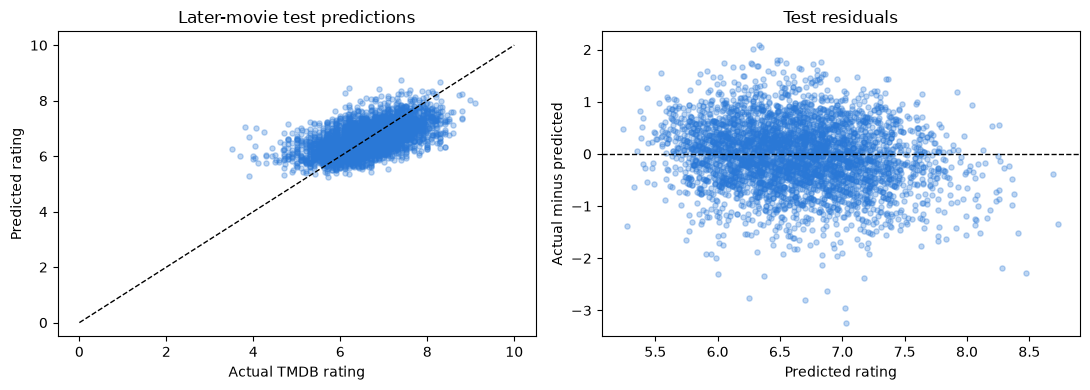

In [9]:
prediction_examples = movies.loc[test_mask, ["title_tmdb", "release_date", "vote_average"]].copy()
prediction_examples["predicted_rating"] = test_predictions
prediction_examples["residual"] = prediction_examples["vote_average"] - prediction_examples["predicted_rating"]
display(prediction_examples.head(10).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, test_predictions, alpha=0.3, s=14, color="#2a78d6")
axes[0].plot([0, 10], [0, 10], "k--", linewidth=1)
axes[0].set(xlabel="Actual TMDB rating", ylabel="Predicted rating", title="Later-movie test predictions")
axes[1].scatter(test_predictions, y_test.to_numpy() - test_predictions, alpha=0.3, s=14, color="#2a78d6")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(xlabel="Predicted rating", ylabel="Actual minus predicted", title="Test residuals")
plt.tight_layout()
plt.show()

## 7. Compare feature groups
Use the same Elastic net regression and three expanding chronological validation splits within the training period. Every version uses the same movies per split and fresh training-only preprocessing. The later test period is excluded.

Start with movie characteristics, then add director, actor, and company/franchise history. Lower validation MAE/RMSE is better; positive improvement means a lower MAE than movie characteristics alone. These are cumulative comparisons, so each added group's result depends on the groups already included.

This section retains the original estimator settings to isolate the cumulative feature comparison. It does not retune each feature version. The tuning section above searches settings using all features; its selection score is not an independent estimate after selection.

In [10]:
movie_features = (
    ["runtime", "log_budget", "release_year", "n_genres", "imdb_director_count"]
    + CATEGORICAL_FEATURES
    + ["is_sequel", "is_english"]
    + [column for column in BINARY_FEATURES if column.startswith("genre_")]
)
director_features = [
    "dir_prior_success_rate_smoothed", "dir_prior_films_log1p", "dir_years_active_log1p",
    "dir_prior_known_films_log1p", "dir_first_film", "dir_no_track_record",
    "dir_prior_rating_smoothed", "dir_prior_rated_films_log1p", "dir_no_rating_history",
]
actor_features = ["lead_actor_films_5yr_backfilled_log1p", "backfill_unavailable"]
company_franchise_features = ["company_films_5yr_log1p", "franchise_prior_films_log1p"]
feature_versions = {
    "Movie characteristics": movie_features,
    "+ Director history": movie_features + director_features,
    "+ Actor history": movie_features + director_features + actor_features,
    "All features": movie_features + director_features + actor_features + company_franchise_features,
}
feature_versions = {name: feature_versions[name] for name in FEATURE_GROUPS_TO_COMPARE}
assert set(feature_versions["All features"]) == set(FEATURE_COLUMNS)
assert all(len(columns) == len(set(columns)) for columns in feature_versions.values())

In [11]:
# Split unique dates so equal release dates never appear on both sides.
training_dates = movies.loc[train_mask, "release_date"]
unique_dates = np.sort(training_dates.unique())
validation_splits = []
split_details = []
for fold, (earlier, later) in enumerate(TimeSeriesSplit(n_splits=N_VALIDATION_SPLITS).split(unique_dates), 1):
    fit_indices = training_dates.index[training_dates.isin(unique_dates[earlier])]
    validation_indices = training_dates.index[training_dates.isin(unique_dates[later])]
    assert movies.loc[fit_indices, "release_date"].max() < movies.loc[validation_indices, "release_date"].min()
    assert set(fit_indices).isdisjoint(validation_indices)
    assert set(fit_indices).union(validation_indices).issubset(set(X_train.index))
    validation_splits.append((fold, fit_indices, validation_indices))
    split_details.append({
        "Fold": fold, "Training movies": len(fit_indices), "Validation movies": len(validation_indices),
        "Training ends": movies.loc[fit_indices, "release_date"].max().date(),
        "Validation starts": movies.loc[validation_indices, "release_date"].min().date(),
        "Validation ends": movies.loc[validation_indices, "release_date"].max().date(),
    })
display(pd.DataFrame(split_details))

,Fold,Training movies,Validation movies,Training ends,Validation starts,Validation ends
0,1,2099,2292,1999-10-08,1999-10-14,2006-10-06
1,2,4391,2417,2006-10-06,2006-10-07,2012-05-09
2,3,6808,2597,2012-05-09,2012-05-10,2017-11-17


In [12]:
comparison_rows = []
for version, columns in feature_versions.items():
    for fold, fit_indices, validation_indices in validation_splits:
        candidate = make_regression_model(columns)
        candidate.fit(X_train.loc[fit_indices, columns], y_train.loc[fit_indices])
        predicted = candidate.predict(X_train.loc[validation_indices, columns])
        assert np.isfinite(predicted).all()
        comparison_rows.append({
            "Version": version, "Fold": fold, "Predictors": len(columns),
            "MAE": mean_absolute_error(y_train.loc[validation_indices], predicted),
            "RMSE": np.sqrt(mean_squared_error(y_train.loc[validation_indices], predicted)),
        })
feature_fold_results = pd.DataFrame(comparison_rows)
feature_comparison = feature_fold_results.groupby("Version", sort=False).agg(
    Predictors=("Predictors", "first"),
    Validation_MAE=("MAE", "mean"),
    MAE_std=("MAE", "std"),
    Validation_RMSE=("RMSE", "mean"),
)
feature_comparison["MAE improvement vs movie-only"] = (
    feature_comparison.loc["Movie characteristics", "Validation_MAE"] - feature_comparison["Validation_MAE"]
)
display(feature_comparison.round(4))
# Check fold consistency: a smaller overall mean can hide a worse individual period.
display(feature_fold_results.pivot(index="Version", columns="Fold", values="MAE").reindex(feature_versions).round(4))
print("Lower validation MAE/RMSE is better; MAE_std shows variation across the three periods.")

,Predictors,Validation_MAE,MAE_std,Validation_RMSE,MAE improvement vs movie-only
Version,,,,,
Movie characteristics,27,0.5230,0.0043,0.6738,0.0000
+ Director history,36,0.5202,0.0033,0.6658,0.0027
+ Actor history,38,0.5206,0.0040,0.6660,0.0024
All features,40,0.5201,0.0034,0.6655,0.0029


Fold,1,2,3
Version,,,
Movie characteristics,0.5279,0.5204,0.5205
+ Director history,0.5221,0.5164,0.5222
+ Actor history,0.5250,0.5173,0.5194
All features,0.5239,0.5174,0.5190


Lower validation MAE/RMSE is better; MAE_std shows variation across the three periods.


## 8. Inspect shrinkage and convergence
Count nonzero coefficients and show the largest absolute weights. Degree-2 terms are transformed-feature effects, not causal effects or direct raw-unit changes. Correlated features can share or exchange weights.

In [13]:
estimator = model.named_steps["regression"]
assert estimator.n_iter_ < estimator.max_iter, "Selected model exhausted its iteration limit."
assert estimator.dual_gap_ <= estimator.tol * np.var(y_train) + 1e-10
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = pd.DataFrame({"Feature": feature_names, "Coefficient": estimator.coef_})
coefficients["Absolute weight"] = coefficients.Coefficient.abs()
print("Nonzero coefficients:", int(coefficients.Coefficient.ne(0).sum()), "of", len(coefficients))
print("Iterations:", estimator.n_iter_, "| Dual gap:", float(estimator.dual_gap_))
display(coefficients.sort_values("Absolute weight", ascending=False).head(15).round(4))


Nonzero coefficients: 90 of 130
Iterations: 88 | Dual gap: 6.411228187743838e-05


,Feature,Coefficient,Absolute weight
129,binary__genre_documentary,0.7477,0.7477
124,binary__genre_animation,0.5793,0.5793
107,binary__is_english,-0.3244,0.3244
112,binary__genre_drama,0.2668,0.2668
119,binary__genre_horror,-0.2607,0.2607
0,numeric__runtime,0.2380,0.2380
6,numeric__dir_prior_rating_smoothed,0.2372,0.2372
113,binary__genre_comedy,-0.1524,0.1524
69,numeric__dir_prior_rating_smoothed^2,0.1196,0.1196
94,categorical__us_certification_Unknown,-0.1060,0.1060


## Interpretation and limits
Compare MAE/RMSE/R² with ridge on the same test movies. A validation winner may perform worse later, and repeated experiments do not constitute independent confirmation. History uses incomplete retrospective snapshots. No current-movie rating, success, revenue or identifier enters the predictor matrix. The app continues using its existing verified ridge pipeline until a separate integration decision.

## Refresh the visualization report
This final cell saves metrics and prediction summaries for [the visualization notebook](../../Data_visualization/model_visualizations.ipynb). It does not write or modify dataset CSVs. Save this notebook before running all cells so report freshness checks match the code.

In [14]:
from pathlib import Path
import importlib.util

report_module_path = Path("../../Data_visualization/model_reports.py")
report_spec = importlib.util.spec_from_file_location("project_model_reports", report_module_path)
report_tools = importlib.util.module_from_spec(report_spec)
report_spec.loader.exec_module(report_tools)
report_path = report_tools.save_model_report(globals(), Path("elastic_net_model.ipynb"))
print("Visualization report saved:", report_path)

Visualization report saved: /Users/waltroou/DS-6021/DS_Final_Project/DS6021_Group2_FinalProject/Data_visualization/results/rating/elastic_net_model.json


## Compare verified later-test results
Compare available linear, ridge and newly added regularized models on matching test movies. This is descriptive reporting after validation selection, not an additional tuning step. Small differences on this already-inspected period do not establish reliable superiority.

In [15]:
comparison_reports = report_tools.load_reports("rating", ['linear_model', 'ridge_model', 'lasso_model', 'elastic_net_model'], "Selected")
regularized_comparison = pd.DataFrame([
    {"Model": key, **report["versions"]["Selected"]["test_metrics"],
     "Validation MAE": report["versions"]["Selected"]["validation"].get("MAE", np.nan)}
    for key, report in comparison_reports.items()
])
display(regularized_comparison.round(4))
print("Models were tuned using chronological training-validation MAE, not these test scores.")


,Model,MAE,RMSE,R2,Validation MAE
0,linear_model,0.5527,0.6959,0.1335,0.5178
1,ridge_model,0.4979,0.6366,0.2750,0.5169
2,lasso_model,0.4943,0.6305,0.2887,0.5086
3,elastic_net_model,0.4949,0.6316,0.2864,0.5093


Models were tuned using chronological training-validation MAE, not these test scores.
